In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Define a realistic global equity portfolio
portfolio_tickers = [
    "AAPL",   # Apple - US technology
    "MSFT",   # Microsoft - US technology
    "NVDA",   # NVIDIA - US semiconductors
    "JPM",    # JPMorgan Chase - US financials
    "JNJ",    # Johnson & Johnson - US healthcare
    "XOM",    # Exxon Mobil - US energy
    "ASML",   # ASML - Netherlands technology
    "NESN.SW",# Nestlé - Switzerland consumer staples
    "SAP.DE", # SAP - Germany technology
    "RYA.IR", # Ryanair - Ireland airlines
    "SPY"     # S&P 500 ETF - benchmark proxy
]

#Define the analysis period
start_date = "2020-01-01"
end_date = "2026-11-11"

print(f"Portfolio contains {len(portfolio_tickers)} securities.")
print(f"Analysis period: {start_date} to {end_date}")

Portfolio contains 11 securities.
Analysis period: 2020-01-01 to 2026-11-11


In [4]:
#Download daily adjusted proce data for all securities
price_data = yf.download(
    tickers=portfolio_tickers,
    start=start_date,
    end=end_date,
    interval="1d",
    group_by="ticker",
    auto_adjust=True,
    progress=True
)
# Show the first few rows
price_data.head()

[*********************100%***********************]  11 of 11 completed


Ticker             JNJ                                                 \
Price             Open        High         Low       Close     Volume   
Date                                                                    
2020-01-02  121.255386  121.380082  120.598698  121.338516  5777000.0   
2020-01-03  119.285276  120.839721  118.869648  119.933655  5752400.0   
2020-01-06  119.700957  119.867206  118.745017  119.784088  7731300.0   
2020-01-07  119.709244  120.906256  117.523048  120.515564  7382900.0   
2020-01-08  120.424140  121.346835  119.451571  120.498962  6605800.0   

Ticker            ASML                                                ...  \
Price             Open        High         Low       Close    Volume  ...   
Date                                                                  ...   
2020-01-02  283.686386  285.616755  283.064903  285.155334  573600.0  ...   
2020-01-03  280.644863  283.196686  280.287037  280.560120  410800.0  ...   
2020-01-06  276.059146  278.460303  275.362316  278.328461  617600.0  ...   
2020-01-07  281.238205  283.639363  280.051735  281.351196  477700.0  ...   
2020-01-08  283.111981  285.494317  282.434003  284.270203  536900.0  ...   

Ticker            MSFT                                                  \
Price             Open        High         Low       Close      Volume   
Date                                                                     
2020-01-02  149.808222  151.648036  149.383652  151.544250  22622100.0   
2020-01-03  149.374235  150.912123  149.128917  149.657272  21116200.0   
2020-01-06  148.204254  150.110119  147.666455  150.044067  20813700.0   
2020-01-07  150.317713  150.647928  148.430722  148.676025  21634100.0   
2020-01-08  149.949746  151.714093  149.025125  151.044205  27746500.0   

Ticker             SPY                                                  
Price             Open        High         Low       Close      Volume  
Date                                                                    
2020-01-02  294.182449  295.409957  293.264086  295.391754  59151200.0  
2020-01-03  292.018452  294.273431  291.963899  293.155029  77709700.0  
2020-01-06  291.409181  294.355207  291.290972  294.273376  55653900.0  
2020-01-07  293.709558  294.182392  293.000335  293.445892  40496400.0  
2020-01-08  293.636955  296.219254  293.391464  295.009949  68296000.0  

[5 rows x 55 columns]

In [8]:
# Check the structure of the download data
print("Data shape:", price_data.shape)
print("\nColumn levels:")
print(price_data.columns.levels[0] if isinstance(price_data.columns, pd.MultiIndex) else price_data.columns)

#Show the last five rows
price_data.tail()

Data shape: (1773, 55)

Column levels:
Index(['AAPL', 'ASML', 'JNJ', 'JPM', 'MSFT', 'NESN.SW', 'NVDA', 'RYA.IR',
       'SAP.DE', 'SPY', 'XOM'],
      dtype='str', name='Ticker')


Ticker             JNJ                                                 \
Price             Open        High         Low       Close     Volume   
Date                                                                    
2026-11-04  272.410004  277.350006  267.670013  276.320007  9619900.0   
2026-11-05  278.920013  281.920013  271.640015  272.320007  9654800.0   
2026-11-06  267.559998  276.410004  265.549988  276.220001  8860000.0   
2026-11-09  278.000000  282.730011  276.200012  282.109985  6899500.0   
2026-11-10  282.000000  283.250000  279.190002  280.779999  7383900.0   

Ticker             ASML                                                    \
Price              Open         High          Low        Close     Volume   
Date                                                                        
2026-11-04  1512.250000  1532.239990  1478.959961  1496.300049  1974900.0   
2026-11-05  1434.260010  1443.479980  1355.050049  1356.650024  4012400.0   
2026-11-06  1446.079956  1447.489990  1409.209961  1424.750000  1903600.0   
2026-11-09  1476.719971  1525.829956  1468.020020  1513.250000  2202700.0   
2026-11-10  1504.619995  1545.709961  1492.000000  1507.849976  1520900.0   

Ticker      ...        MSFT                                                  \
Price       ...        Open        High         Low       Close      Volume   
Date        ...                                                               
2026-11-04  ...  543.700012  559.150024  542.299988  555.799988  50807800.0   
2026-11-05  ...  554.940002  557.619995  532.679993  535.929993  42507900.0   
2026-11-06  ...  525.690002  538.330017  524.469971  530.609985  26956400.0   
2026-11-09  ...  544.489990  548.280029  538.700012  545.179993  25337400.0   
2026-11-10  ...  542.979980  544.190002  526.369995  533.159973  26940900.0   

Ticker             SPY                                                   
Price             Open        High         Low       Close       Volume  
Date                                                                     
2026-11-04  762.989990  775.640015  762.640015  766.809998   62126400.0  
2026-11-05  765.469971  765.969971  732.710022  733.000000  125892800.0  
2026-11-06  734.820007  742.210022  734.580017  735.289978   58978800.0  
2026-11-09  741.950012  755.419983  741.030029  752.690002   50281200.0  
2026-11-10  747.940002  752.140015  744.859985  749.919983   40698600.0  

[5 rows x 55 columns]

In [9]:
# Check for missing values
missing_values = price_data.isnull().sum()
print(missing_values)

Ticker   Price 
JNJ      Open      49
         High      49
         Low       49
         Close     49
         Volume    49
ASML     Open      49
         High      49
         Low       49
         Close     49
         Volume    49
RYA.IR   Open      26
         High      26
         Low       26
         Close     26
         Volume    26
SAP.DE   Open      25
         High      25
         Low       25
         Close     25
         Volume    25
JPM      Open      49
         High      49
         Low       49
         Close     49
         Volume    49
NVDA     Open      49
         High      49
         Low       49
         Close     49
         Volume    49
NESN.SW  Open      46
         High      46
         Low       46
         Close     46
         Volume    46
AAPL     Open      49
         High      49
         Low       49
         Close     49
         Volume    49
XOM      Open      49
         High      49
         Low       49
         Close     49
         Volume 

In [13]:
#Create the data raw data folder if it does not already exist
raw_data_folder = Path("../data/raw")
raw_data_folder.mkdir(parents=True, exist_ok=True)

#Save the downloaded data
output_file = raw_data_folder / "global_equity_prices.csv"

price_data.to_csv(output_file)

print(f"Data saved to:{output_file}")
print(f"File size: {output_file.stat().st_size / 1024:.1f} KB")

Data saved to:..\data\raw\global_equity_prices.csv
File size: 1582.5 KB


In [14]:
#Read the saved file back to verify it works
saved_data = pd.read_csv(output_file, header=[0,1], index_col=0, parse_dates=True)

print(saved_data.shape)
saved_data.tail()

(1773, 55)


Ticker             JNJ                                                 \
Price             Open        High         Low       Close     Volume   
Date                                                                    
2026-11-04  272.410004  277.350006  267.670013  276.320007  9619900.0   
2026-11-05  278.920013  281.920013  271.640015  272.320007  9654800.0   
2026-11-06  267.559998  276.410004  265.549988  276.220001  8860000.0   
2026-11-09  278.000000  282.730011  276.200012  282.109985  6899500.0   
2026-11-10  282.000000  283.250000  279.190002  280.779999  7383900.0   

Ticker             ASML                                                    \
Price              Open         High          Low        Close     Volume   
Date                                                                        
2026-11-04  1512.250000  1532.239990  1478.959961  1496.300049  1974900.0   
2026-11-05  1434.260010  1443.479980  1355.050049  1356.650024  4012400.0   
2026-11-06  1446.079956  1447.489990  1409.209961  1424.750000  1903600.0   
2026-11-09  1476.719971  1525.829956  1468.020020  1513.250000  2202700.0   
2026-11-10  1504.619995  1545.709961  1492.000000  1507.849976  1520900.0   

Ticker      ...        MSFT                                                  \
Price       ...        Open        High         Low       Close      Volume   
Date        ...                                                               
2026-11-04  ...  543.700012  559.150024  542.299988  555.799988  50807800.0   
2026-11-05  ...  554.940002  557.619995  532.679993  535.929993  42507900.0   
2026-11-06  ...  525.690002  538.330017  524.469971  530.609985  26956400.0   
2026-11-09  ...  544.489990  548.280029  538.700012  545.179993  25337400.0   
2026-11-10  ...  542.979980  544.190002  526.369995  533.159973  26940900.0   

Ticker             SPY                                                   
Price             Open        High         Low       Close       Volume  
Date                                                                     
2026-11-04  762.989990  775.640015  762.640015  766.809998   62126400.0  
2026-11-05  765.469971  765.969971  732.710022  733.000000  125892800.0  
2026-11-06  734.820007  742.210022  734.580017  735.289978   58978800.0  
2026-11-09  741.950012  755.419983  741.030029  752.690002   50281200.0  
2026-11-10  747.940002  752.140015  744.859985  749.919983   40698600.0  

[5 rows x 55 columns]

In [4]:
#Load the saved raw price data
raw_data_file = Path("../data/raw/global_equity_prices.csv")

price_data = pd.read_csv(
    raw_data_file,
    header=[0,1],
    index_col=0,
    parse_dates=True
)

#Inspect the data
print(price_data.shape)
price_data.tail()

(1773, 55)


Ticker             JNJ                                                 \
Price             Open        High         Low       Close     Volume   
Date                                                                    
2026-11-04  272.410004  277.350006  267.670013  276.320007  9619900.0   
2026-11-05  278.920013  281.920013  271.640015  272.320007  9654800.0   
2026-11-06  267.559998  276.410004  265.549988  276.220001  8860000.0   
2026-11-09  278.000000  282.730011  276.200012  282.109985  6899500.0   
2026-11-10  282.000000  283.250000  279.190002  280.779999  7383900.0   

Ticker             ASML                                                    \
Price              Open         High          Low        Close     Volume   
Date                                                                        
2026-11-04  1512.250000  1532.239990  1478.959961  1496.300049  1974900.0   
2026-11-05  1434.260010  1443.479980  1355.050049  1356.650024  4012400.0   
2026-11-06  1446.079956  1447.489990  1409.209961  1424.750000  1903600.0   
2026-11-09  1476.719971  1525.829956  1468.020020  1513.250000  2202700.0   
2026-11-10  1504.619995  1545.709961  1492.000000  1507.849976  1520900.0   

Ticker      ...        MSFT                                                  \
Price       ...        Open        High         Low       Close      Volume   
Date        ...                                                               
2026-11-04  ...  543.700012  559.150024  542.299988  555.799988  50807800.0   
2026-11-05  ...  554.940002  557.619995  532.679993  535.929993  42507900.0   
2026-11-06  ...  525.690002  538.330017  524.469971  530.609985  26956400.0   
2026-11-09  ...  544.489990  548.280029  538.700012  545.179993  25337400.0   
2026-11-10  ...  542.979980  544.190002  526.369995  533.159973  26940900.0   

Ticker             SPY                                                   
Price             Open        High         Low       Close       Volume  
Date                                                                     
2026-11-04  762.989990  775.640015  762.640015  766.809998   62126400.0  
2026-11-05  765.469971  765.969971  732.710022  733.000000  125892800.0  
2026-11-06  734.820007  742.210022  734.580017  735.289978   58978800.0  
2026-11-09  741.950012  755.419983  741.030029  752.690002   50281200.0  
2026-11-10  747.940002  752.140015  744.859985  749.919983   40698600.0  

[5 rows x 55 columns]

In [6]:
#Extract adjusted close prices
adjusted_close = price_data.xs("Close", axis=1, level=1)

#Inspect the result
adjusted_close.tail()

Ticker,JNJ,ASML,RYA.IR,SAP.DE,JPM,NVDA,NESN.SW,AAPL,XOM,MSFT,SPY
Date,,,,,,,,,,,
2026-11-04,276.320007,1496.300049,25.330000,214.300003,352.109985,200.130005,85.900002,349.510010,169.270004,555.799988,766.809998
2026-11-05,272.320007,1356.650024,24.980000,215.750000,337.339996,181.600006,87.230003,344.170013,165.300003,535.929993,733.000000
2026-11-06,276.220001,1424.750000,25.690001,210.750000,334.489990,186.639999,85.849998,342.369995,165.869995,530.609985,735.289978
2026-11-09,282.109985,1513.250000,26.420000,211.649994,342.079987,178.669998,86.129997,350.690002,164.729996,545.179993,752.690002
2026-11-10,280.779999,1507.849976,26.610001,209.949997,342.070007,168.889999,86.410004,348.510010,164.470001,533.159973,749.919983


In [17]:
#Check missing values by security
missing_by_ticker = adjusted_close.isnull().sum()
print(missing_by_ticker)

#Check the first and last available date
print("\nFirst date:", adjusted_close.index.min())
print("Last Date:" , adjusted_close.index.max())

Ticker
JNJ        49
ASML       49
RYA.IR     26
SAP.DE     25
JPM        49
NVDA       49
NESN.SW    46
AAPL       49
XOM        49
MSFT       49
SPY        49
dtype: int64

First date: 2020-01-02 00:00:00
Last Date: 2026-11-10 00:00:00


In [19]:
#Calculate daily simple returns
daily_returns = adjusted_close.pct_change().dropna()
#Inspect the first few rows
daily_returns.head()

Ticker,JNJ,ASML,RYA.IR,SAP.DE,JPM,NVDA,NESN.SW,AAPL,XOM,MSFT,SPY
Date,,,,,,,,,,,
2020-01-06,-0.001247,-0.007954,-0.014920,-0.007471,-0.000795,0.004194,-0.000564,0.007968,0.007678,0.002585,0.003815
2020-01-07,0.006107,0.010860,0.019966,0.004516,-0.017000,0.012107,-0.009975,-0.004703,-0.008184,-0.009118,-0.002812
2020-01-08,-0.000138,0.010375,0.001688,0.005995,0.007801,0.001875,-0.016160,0.016086,-0.015080,0.015928,0.005330
2020-01-09,0.002966,-0.001689,0.025270,0.019368,0.003651,0.010983,-0.004058,0.021241,0.007656,0.012493,0.006780
2020-01-10,-0.002270,-0.017254,0.056194,0.004872,-0.009968,0.005349,-0.001358,0.002260,-0.008888,-0.004627,-0.002878


In [22]:
#Securities included in the portfolio
portfolio_securities = ["AAPL", "MSFT", "NVDA", "JPM", "JNJ", "XOM", "ASML", "NESN.SW","SAP.DE", "RYA.IR"]

#Equal weight for each security
portfolio_weight = 1/len(portfolio_securities)

#Create a dictionary of weights
portfolio_weights = {
    ticker: portfolio_weight for ticker in portfolio_securities    
}

#Convert to a pandas Series
weights = pd.Series(portfolio_weights)

#Check that weights sum to 1
print(weights)
print("\nTotal portfolio weight:", weights.sum())

AAPL       0.1
MSFT       0.1
NVDA       0.1
JPM        0.1
JNJ        0.1
XOM        0.1
ASML       0.1
NESN.SW    0.1
SAP.DE     0.1
RYA.IR     0.1
dtype: float64

Total portfolio weight: 1.0


In [23]:
# Select only portfolio securities
portfolio_returns = daily_returns[portfolio_securities]

#Calculate daily portfolio return using weights    
portfolio_daily_return= portfolio_returns.mul(weights, axis=1).sum(axis=1)

#Convert to a DataFrame for easier analysis
portfolio_daily_return = portfolio_daily_return.to_frame(name="Portfolio Return")

#Inspect the result 
portfolio_daily_return.head()

,Portfolio Return
Date,
2020-01-06,-0.001053
2020-01-07,0.000458
2020-01-08,0.002837
2020-01-09,0.009788
2020-01-10,0.002431


In [25]:
#Extract benchmark returns
benchmark_daily_return = daily_returns[["SPY"]].copy()
benchmark_daily_return.columns = ["Benchmark Return"]

#Combine portfolio and benchhmark returns
performance_data = portfolio_daily_return.join(benchmark_daily_return, how="inner")

#Inspect the result
performance_data.head()

,Portfolio Return,Benchmark Return
Date,,
2020-01-06,-0.001053,0.003815
2020-01-07,0.000458,-0.002812
2020-01-08,0.002837,0.005330
2020-01-09,0.009788,0.006780
2020-01-10,0.002431,-0.002878


In [29]:
#Start with hypothetical 1000 euro investment
inital_investment = 1000

# Calculate portfolio value
portfolio_cumulative_value = inital_investment * (1 + performance_data["Portfolio Return"]).cumprod()

#Calculate the cumulative benchmark value
benchmark_cumulative_value = inital_investment * (1 + performance_data["Benchmark Return"]).cumprod()

#Combine into one DataFrame
cumulative_performance = pd.DataFrame({
    "Portfolio": portfolio_cumulative_value,
    "Benchmark": benchmark_cumulative_value
})

#Inspect the result
cumulative_performance.tail()

,Portfolio,Benchmark
Date,,
2026-11-04,4566.410767,2568.252679
2026-11-05,4425.585481,2455.013914
2026-11-06,4452.821572,2462.683666
2026-11-09,4517.059479,2520.961022
2026-11-10,4476.188279,2511.683482


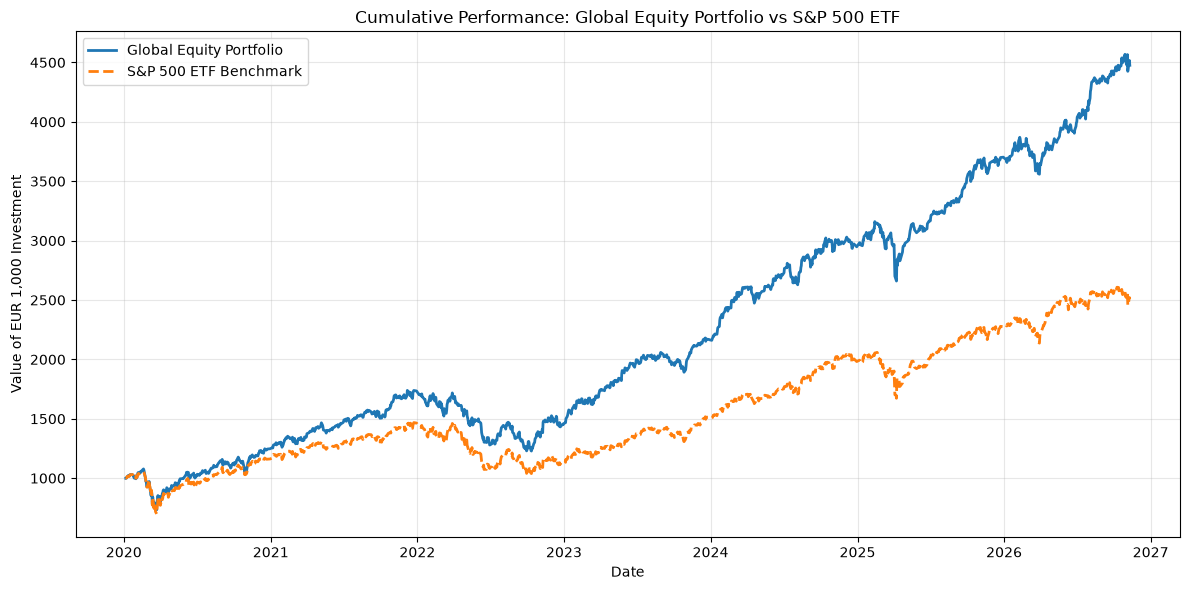

In [31]:
#Plot cumulative performance
plt.figure(figsize=(12,6))

plt.plot(
    cumulative_performance.index,
    cumulative_performance["Portfolio"],
    label="Global Equity Portfolio",
    linewidth=2
)

plt.plot(
    cumulative_performance.index,
    cumulative_performance["Benchmark"],
    label="S&P 500 ETF Benchmark",
    linewidth=2,
    linestyle="--"    
)

plt.title("Cumulative Performance: Global Equity Portfolio vs S&P 500 ETF")
plt.xlabel("Date")
plt.ylabel("Value of EUR 1,000 Investment")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [36]:
## 1.Did the portfolio end above or below €1,000?
## Above 1000#
2 Did the portfolio outperform or underperform the benchmark
# Outperform the benchmark?# 
. During which periods did the portfolio experience the largest decline
# Between 2022 and 2023, 2025 and 2026s# 44. What could explain the difference between the portfolio and benchmark performance?

SyntaxError: invalid syntax (1798628938.py, line 4)

In [40]:
#Create processed data folder
processed_data_folder = Path("../data/processed")
processed_data_folder.mkdir(parents=True, exist_ok=True)

# Save daily returns
daily_returns.to_csv(processed_data_folder / "daily_returns.csv")

# Save portfolio and benchmark performance
performance_data.to_csv(processed_data_folder / "portfolio_benchmark_daily_returns.csv")

# Save cumulative performance
cumulative_performance.to_csv(processed_data_folder / "cumulative_performance.csv")

print("Processed data saved successfully")

Processed data saved successfully
